# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [1]:
import pandas as pd
import plotly.express as px


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [2]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   object 
 1   continent  1704 non-null   object 
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   object 
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 106.6+ KB
None
Years: [1952, 1957, 1962, 1967, 1972, 1977, 1982, 1987, 1992, 1997, 2002, 2007]
Continents: ['Asia' 'Europe' 'Africa' 'Americas' 'Oceania']
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.5  2.960121e+07     7215.3    425.9
std      17.3     12.9  1.061579e+08     9857.5    248.3
min    1952.0     23.6  6.001100e+04      241.2      4.0


## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


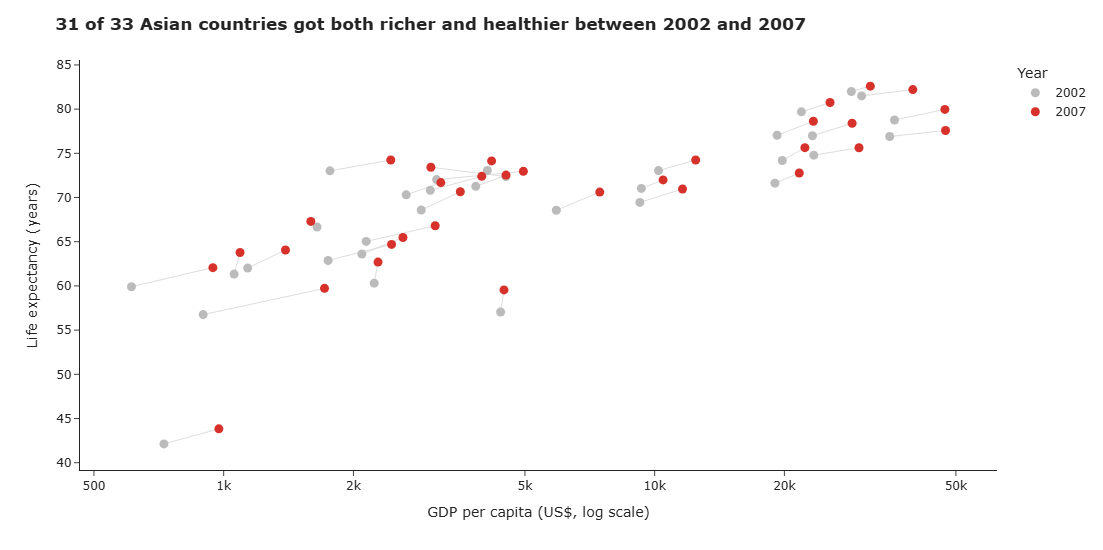

In [5]:
# Task 1
import plotly.graph_objects as go

continent = "Asia"
d = df[(df["continent"] == continent) & (df["year"].isin([2002, 2007]))].copy()
d["year"] = d["year"].astype(str)

fig = px.scatter(
    d, x="gdpPercap", y="lifeExp", color="year", log_x=True,
    color_discrete_map={"2002": "#BBBBBB", "2007": "#D7312B"},
    hover_name="country",
    labels={"gdpPercap": "GDP per capita (US$, log scale)", "lifeExp": "Life expectancy (years)", "year": "Year"},
)

# Thin lines joining each country's 2002 and 2007 points, to show the direction of change
wide = d.pivot(index="country", columns="year", values=["gdpPercap", "lifeExp"])
xs, ys = [], []
for c in wide.index:
    xs += [wide.loc[c, ("gdpPercap", "2002")], wide.loc[c, ("gdpPercap", "2007")], None]
    ys += [wide.loc[c, ("lifeExp", "2002")], wide.loc[c, ("lifeExp", "2007")], None]
fig.add_trace(go.Scatter(x=xs, y=ys, mode="lines", line=dict(color="#DDDDDD", width=1),
                         hoverinfo="skip", showlegend=False))
fig.data = (fig.data[-1],) + fig.data[:-1]   # draw the lines behind the dots

# Insight title calculated from the data
better = ((wide[("gdpPercap", "2007")] > wide[("gdpPercap", "2002")]) &
          (wide[("lifeExp", "2007")] > wide[("lifeExp", "2002")])).sum()
fig.update_layout(
    title=f"<b>{better} of {len(wide)} Asian countries got both richer and healthier between 2002 and 2007</b>",
    template="simple_white", width=900, height=550,
    xaxis=dict(showgrid=False), yaxis=dict(showgrid=False),
)
fig.update_traces(marker=dict(size=9))
fig.update_xaxes(tickvals=[500, 1000, 2000, 5000, 10000, 20000, 50000],
                 ticktext=["500", "1k", "2k", "5k", "10k", "20k", "50k"])
fig.show()


## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


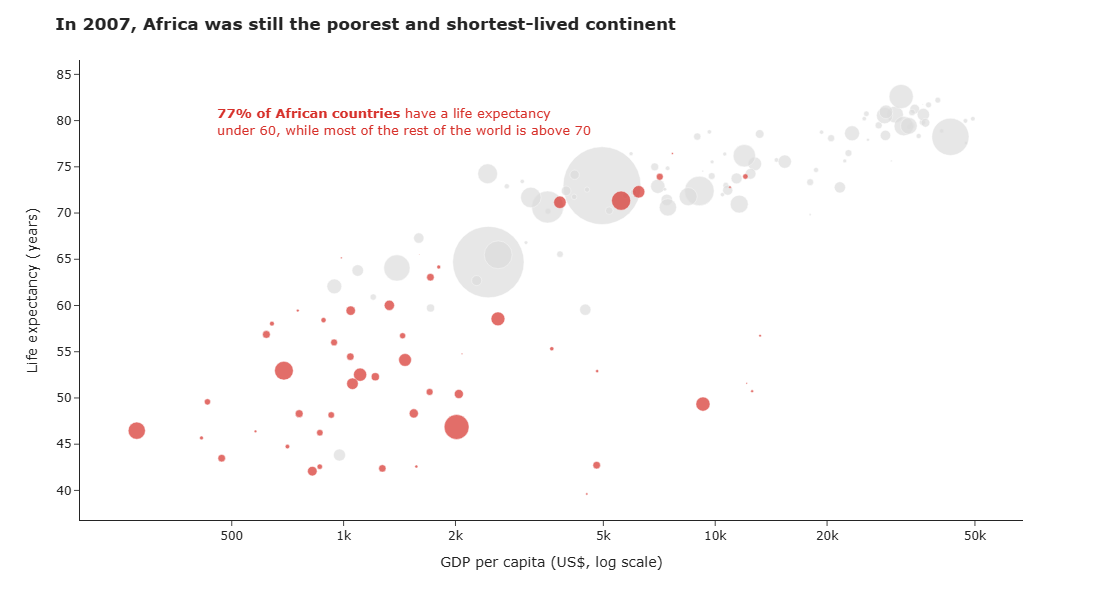

In [6]:
# Task 2
import math

highlight = "Africa"
d07 = df[df["year"] == 2007].copy()
d07["group"] = d07["continent"].where(d07["continent"] == highlight, "Other continents")

fig = px.scatter(
    d07, x="gdpPercap", y="lifeExp", size="pop", size_max=55,
    color="group", log_x=True, hover_name="country",
    color_discrete_map={highlight: "#D7312B", "Other continents": "#DDDDDD"},
    category_orders={"group": ["Other continents", highlight]},   # highlighted bubbles on top
    labels={"gdpPercap": "GDP per capita (US$, log scale)", "lifeExp": "Life expectancy (years)"},
)

# Annotation explaining the story, calculated from the data
africa = d07[d07["continent"] == highlight]
share = (africa["lifeExp"] < 60).mean()
fig.add_annotation(
    x=math.log10(450), y=80, xanchor="left", showarrow=False, align="left",
    text=(f"<b>{share:.0%} of African countries</b> have a life expectancy<br>"
          f"under 60, while most of the rest of the world is above 70"),
    font=dict(color="#D7312B", size=13),
)

fig.update_layout(
    title="<b>In 2007, Africa was still the poorest and shortest-lived continent</b>",
    template="simple_white", showlegend=False, width=950, height=600,
    xaxis=dict(showgrid=False), yaxis=dict(showgrid=False),
)
fig.update_traces(marker=dict(line=dict(width=0.5, color="white")))
fig.update_xaxes(tickvals=[500, 1000, 2000, 5000, 10000, 20000, 50000],
                 ticktext=["500", "1k", "2k", "5k", "10k", "20k", "50k"])
fig.show()
